In [2]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


[ZGA] 共读取 3314 个 ZGA 基因
[DEPIGs] 共读取 4063 个 DEPIGs 基因
[Info] 时间映射文件中共有 298 个样本
[TAD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[Expr] 原始矩阵形状: (20289, 118) (基因 × 细胞)

===== 构建 ZGA 数据集 =====
[ZGA][TAD] 筛选后形状: (3110, 298)
[ZGA][TAD] 有效细胞数（在时间映射中）: 298
[ZGA][Expr] 筛选后形状: (3313, 118)
[ZGA][Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[ZGA][TLD ∩ APA] 共有细胞数: 287
[ZGA][TLD only] 仅 TLD 有: 11
[ZGA][APA only] 仅 APA 有: 0

[ZGA] 最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

===== 构建 DEPIGs 数据集 =====
[DEPIGs][TAD] 筛选后形状: (4006, 298)
[DEPIGs][TAD] 有效细胞数（在时间映射中）: 298
[DEPIGs][Expr] 筛选后形状: (3930, 118)
[DEPIGs][Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[DEPIGs][TLD ∩ APA] 共有细胞数: 287
[DEPIGs][TLD only] 仅 TLD 有: 11
[DEPIGs][APA only] 仅 APA 有: 0

[DEPIGs] 最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

全局时间范围: [0.0000, 14.3736]
2C/4C 分界点 (归一化后): 0.3826

===== ZGA：每个阶段内每个 bin 的细胞数量统计 ====

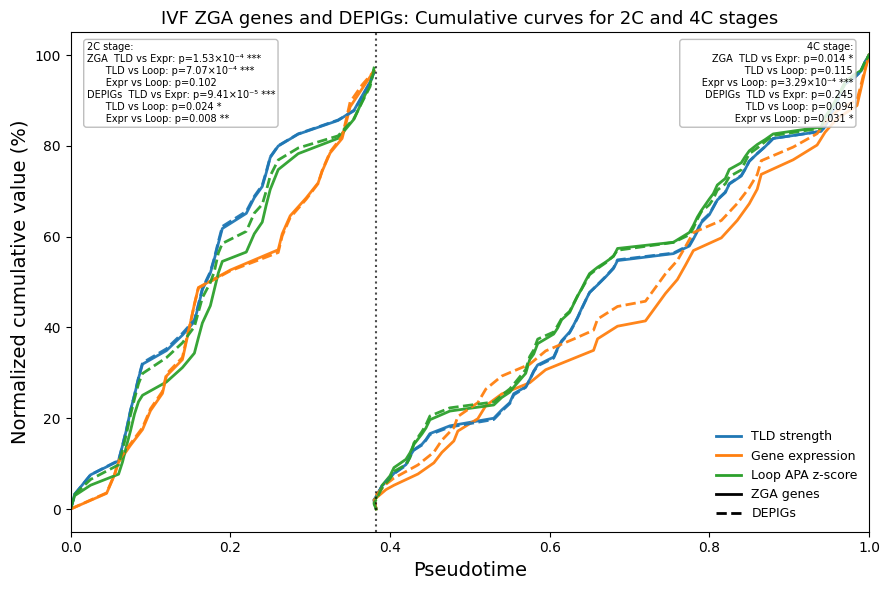

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu
from matplotlib.lines import Line2D

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 5.5              # 2C/4C 分界阈值
ALPHA = 0.05

data_sources_keys = ['TLD', 'Expr', 'APA']
stages = ['2C', '4C']

# ========== 0. 读取 ZGA 和 DEPIGs 基因列表 ==========
zga_genes = set(pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt",
    header=None
)[0].tolist())
print(f"[ZGA] 共读取 {len(zga_genes)} 个 ZGA 基因")

depig_genes = set(pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_2C_4C_diffEPI_overlap_id.txt",
    header=None
)[0].tolist())
print(f"[DEPIGs] 共读取 {len(depig_genes)} 个 DEPIGs 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据 ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')

# ========== 3. 读取转录组数据和伪时间 ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))


# ========== 函数：读取 APA 文件 ==========
def load_apa(apa_path):
    apa_df = pd.read_csv(apa_path, sep="\t")
    print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")

    apa_df = apa_df.iloc[:, :2]
    apa_df.columns = ['sample', 'z_score']
    apa_df['sample'] = (
        apa_df['sample']
        .astype(str)
        .str.strip()
        .str.replace('"', '')
        .str.replace("'", "")
    )
    print(f"[APA] 原始读取的样本数: {len(apa_df)}")

    apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
    print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")
    return apa_df


# ========== 函数：构建某一个基因集的 TLD / Expr / APA 数据 ==========
def build_dataset(gene_set, apa_path, dataset_name):
    print(f"\n===== 构建 {dataset_name} 数据集 =====")

    # ---- TLD strength ----
    tad_sub = tad_strength.loc[tad_strength.index.intersection(gene_set)]
    print(f"[{dataset_name}][TAD] 筛选后形状: {tad_sub.shape}")

    cell_means_tad = tad_sub.mean(axis=0)
    valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
    print(f"[{dataset_name}][TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

    # ---- 转录组 ----
    expr_sub = expr.loc[expr.index.intersection(gene_set)]
    print(f"[{dataset_name}][Expr] 筛选后形状: {expr_sub.shape}")

    expr_mean = np.log2(expr_sub + 1).mean(axis=0)
    valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
    print(f"[{dataset_name}][Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

    times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
    values_expr = expr_mean[valid_cells_expr].values

    # ---- APA ----
    apa_df = load_apa(apa_path)

    # ---- TLD 和 APA 取共有细胞 ----
    tad_cells_set = set(valid_cells_tad)
    apa_cells_set = set(apa_df['sample'])
    common_cells = tad_cells_set & apa_cells_set

    print(f"\n[{dataset_name}][TLD ∩ APA] 共有细胞数: {len(common_cells)}")
    print(f"[{dataset_name}][TLD only] 仅 TLD 有: {len(tad_cells_set - apa_cells_set)}")
    print(f"[{dataset_name}][APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

    if len(common_cells) == 0:
        raise ValueError(f"{dataset_name}: TLD 和 APA 没有共有细胞，无法继续分析。")

    common_cells_list = sorted(common_cells)

    # TLD：共有细胞
    tad_strength_common = tad_sub[common_cells_list]
    cell_means_tad_common = tad_strength_common.mean(axis=0)

    times_tad = np.array([sample_to_time[c] for c in common_cells_list])
    values_tad = cell_means_tad_common[common_cells_list].values

    idx = np.argsort(times_tad)
    times_tad, values_tad = times_tad[idx], values_tad[idx]

    # APA：共有细胞
    apa_df_common = apa_df[apa_df['sample'].isin(common_cells_list)]
    apa_times = apa_df_common['sample'].map(sample_to_time).values
    apa_vals = apa_df_common['z_score'].values

    idx = np.argsort(apa_times)
    apa_times, apa_vals = apa_times[idx], apa_vals[idx]

    # Expr：排序
    idx_expr = np.argsort(times_expr)
    times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

    print(f"\n[{dataset_name}] 最终用于分析的细胞数:")
    print(f"  TLD: {len(times_tad)}")
    print(f"  APA: {len(apa_times)}")
    print(f"  Expr: {len(times_expr)}")

    return {
        'TLD': (times_tad, values_tad),
        'Expr': (times_expr, values_expr),
        'APA': (apa_times, apa_vals)
    }


# ========== 构建 ZGA 和 DEPIGs 两套数据 ==========
zga_apa_path = "/home/lihaoxing/jupyter/IVF_ZGA_APA_zscore_summary.txt"
depig_apa_path = "/home/lihaoxing/jupyter/IVF_diffEPI_APA_zscore_summary.txt"

data_sources_all = {
    'ZGA': build_dataset(zga_genes, zga_apa_path, 'ZGA'),
    'DEPIGs': build_dataset(depig_genes, depig_apa_path, 'DEPIGs')
}


# ========== 函数：构建分箱累积曲线 ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])

    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size

    grouped = (
        df.groupby('bin')
        .agg({'value': 'mean', 'time': 'count'})
        .reset_index()
        .sort_values('bin')
    )

    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values

    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100

    return x, cum, counts


def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time

    t = times[mask]
    v = values[mask]

    if len(t) == 0:
        return np.array([]), np.array([])

    idx = np.argsort(t)
    return t[idx], v[idx]


def build_curves(data_sources, threshold_norm):
    curve_data = {}
    bin_count_info = {}

    for name, (t, v) in data_sources.items():
        curve_data[name] = {}
        bin_count_info[name] = {}

        for st in stages:
            t_stage, v_stage = get_stage_data(t, v, st)

            if len(t_stage) == 0:
                curve_data[name][st] = (np.array([]), np.array([]))
                bin_count_info[name][st] = np.array([])
                continue

            # 阶段内独立归一化到固定分割点
            t_min = t_stage.min()
            t_max = t_stage.max()

            if t_max == t_min:
                if st == '2C':
                    t_norm = np.full_like(t_stage, 0.0, dtype=float)
                else:
                    t_norm = np.full_like(t_stage, 1.0, dtype=float)
            else:
                if st == '2C':
                    t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
                else:
                    t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)

            x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
            bin_count_info[name][st] = counts
            curve_data[name][st] = (x_raw, cum)

    return curve_data, bin_count_info


# ========== 计算统一分割点 ==========
all_times_list = []
for ds in data_sources_all.values():
    for name in data_sources_keys:
        t, _ = ds[name]
        all_times_list.append(t)

all_times = np.concatenate(all_times_list)
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)

print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 构建曲线 ==========
curve_data_all = {}
bin_count_all = {}

for ds_name, ds in data_sources_all.items():
    curve_data_all[ds_name], bin_count_all[ds_name] = build_curves(ds, threshold_norm)


# ========== 打印 bin 细胞数量统计 ==========
def print_bin_stats(dataset_name, bin_count_info):
    print(f"\n===== {dataset_name}：每个阶段内每个 bin 的细胞数量统计 =====")
    for name in data_sources_keys:
        print(f"\n{name}:")
        for st in stages:
            counts = bin_count_info[name][st]
            if len(counts) == 0:
                print(f"  {st}: 无数据")
                continue

            avg = np.mean(counts)
            std = np.std(counts)
            total = np.sum(counts)
            n_bins = len(counts)
            print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
                  f"平均每 bin = {avg:.2f} ± {std:.2f} "
                  f"(min = {counts.min()}, max = {counts.max()})")


for ds_name in data_sources_all:
    print_bin_stats(ds_name, bin_count_all[ds_name])


# ========== 统计检验 ==========
def compute_pvalues(curve_data, stage):
    all_x = []
    for name in data_sources_keys:
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)

    if len(all_x) == 0:
        return np.nan, np.nan, np.nan

    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan

    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}

    for name in data_sources_keys:
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan, dtype=float)
        else:
            f = interp1d(
                x, cum, kind='previous',
                fill_value=(cum[0], cum[-1]),
                bounds_error=False
            )
            interp_vals[name] = f(grid)

    mask = ~(
        np.isnan(interp_vals['TLD']) |
        np.isnan(interp_vals['Expr']) |
        np.isnan(interp_vals['APA'])
    )

    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan

    p_tad_expr = mannwhitneyu(
        interp_vals['TLD'][mask],
        interp_vals['Expr'][mask],
        alternative='two-sided'
    ).pvalue

    p_tad_apa = mannwhitneyu(
        interp_vals['TLD'][mask],
        interp_vals['APA'][mask],
        alternative='two-sided'
    ).pvalue

    p_expr_apa = mannwhitneyu(
        interp_vals['Expr'][mask],
        interp_vals['APA'][mask],
        alternative='two-sided'
    ).pvalue

    return p_tad_expr, p_tad_apa, p_expr_apa


p_values_all = {
    ds_name: {
        st: compute_pvalues(curve_data_all[ds_name], st)
        for st in stages
    }
    for ds_name in data_sources_all
}


# ========== 格式化 p 值：不用 e 表示 ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")


def format_p(p):
    if np.isnan(p):
        return "NA"

    if p <= 0:
        s = "p<1×10⁻³⁰⁰"
    elif p >= 0.001:
        s = f"p={p:.3f}"
    else:
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        exp_str = str(exp).translate(SUP_MAP)
        s = f"p={mant:.2f}×10{exp_str}"

    if p < 0.001:
        s += " ***"
    elif p < 0.01:
        s += " **"
    elif p < ALPHA:
        s += " *"

    return s


# ========== 按 stage 生成 p 值文本（2C 左，4C 右） ==========
def build_p_text_by_stage(st):
    lines = [f"{st} stage:"]
    for ds_name in ['ZGA', 'DEPIGs']:
        p1, p2, p3 = p_values_all[ds_name][st]
        lines.append(f"{ds_name}  TLD vs Expr: {format_p(p1)}")
        lines.append(f"      TLD vs Loop: {format_p(p2)}")
        lines.append(f"      Expr vs Loop: {format_p(p3)}")
    return "\n".join(lines)


# ========== 绘图 ==========
fig, ax = plt.subplots(figsize=(9.0, 6.0))

colors = {
    'TLD': '#1f77b4',
    'Expr': '#ff7f0e',
    'APA': '#2ca02c'
}

line_styles = {
    'ZGA': '-',
    'DEPIGs': '--'
}

# 画曲线：颜色 = 特征，线型 = 基因集
for ds_name in data_sources_all:
    for name in data_sources_keys:
        for st in stages:
            x_norm, cum = curve_data_all[ds_name][name][st]

            if len(x_norm) == 0:
                continue

            if st == '2C':
                x_plot = x_norm
                cum_plot = cum - cum[0]
            else:
                x_plot = np.insert(x_norm, 0, threshold_norm)
                cum_plot = np.insert(cum, 0, 0.0)

            ax.plot(
                x_plot, cum_plot,
                color=colors[name],
                linestyle=line_styles[ds_name],
                linewidth=2,
                alpha=0.95
            )

# 2C/4C 分割线
ax.axvline(
    threshold_norm,
    color='black',
    linestyle=':',
    linewidth=1.5,
    alpha=0.7
)

# p 值文本框：2C 在左，4C 在右
ax.text(
    0.02, 0.98,
    build_p_text_by_stage('2C'),
    transform=ax.transAxes,
    fontsize=7.0,
    verticalalignment='top',
    horizontalalignment='left',
    linespacing=1.25,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='0.7')
)

ax.text(
    0.98, 0.98,
    build_p_text_by_stage('4C'),
    transform=ax.transAxes,
    fontsize=7.0,
    verticalalignment='top',
    horizontalalignment='right',
    linespacing=1.25,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='0.7')
)

# 自定义图例：颜色表示特征，线型表示基因集
legend_elements = [
    Line2D([0], [0], color=colors['TLD'], lw=2, label='TLD strength'),
    Line2D([0], [0], color=colors['Expr'], lw=2, label='Gene expression'),
    Line2D([0], [0], color=colors['APA'], lw=2, label='Loop APA z-score'),
    Line2D([0], [0], color='black', lw=2, linestyle='-', label='ZGA genes'),
    Line2D([0], [0], color='black', lw=2, linestyle='--', label='DEPIGs')
]

ax.legend(
    handles=legend_elements,
    loc='lower right',
    fontsize=9,
    frameon=False
)

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('IVF ZGA genes and DEPIGs: Cumulative curves for 2C and 4C stages', fontsize=13)

ax.set_xlim(0, 1)

plt.tight_layout()
plt.savefig(
    'IVF_TLD_Expr_APA_Cumulative_Split_Normalized_ZGA_vs_DEPIGs.svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

[all] 共读取 20289 个 all 基因
[Info] 时间映射文件中共有 298 个样本
[TLD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[TLD] 筛选 ZGA 基因后形状: (18956, 298)
[TLD] 有效细胞数（在时间映射中）: 298
[Expr] 原始矩阵形状: (20289, 118) (基因 × 细胞)
[Expr] 筛选 ZGA 基因后形状: (20289, 118)
[Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[TLD ∩ APA] 共有细胞数: 287
[TLD only] 仅 TLD 有: 11
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

全局时间范围: [0.0000, 14.3736]
2C/4C 分界点 (归一化后): 0.3826

===== 每个阶段内每个 bin 的细胞数量统计 =====

TLD:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)

Expr:
  2C: 总细胞数 = 44, bin 数 = 27, 平均每 bin = 1.63 ± 1.39 (min = 1, max = 8)
  4C: 总细胞数 = 58, bin 数 = 36, 平均每 bin = 1.61 ± 1.36 (min = 1, max = 8)

APA:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)


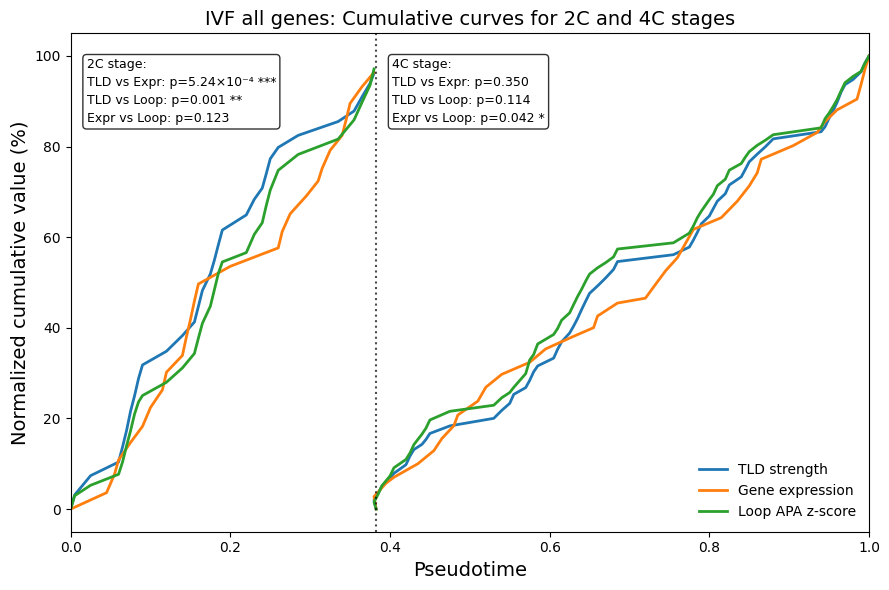

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 5.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 all 基因列表 ==========
zga_genes = set(pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/expressed_genes.txt", header=None)[0].tolist())
print(f"[all] 共读取 {len(zga_genes)} 个 all 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 ZGA 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TLD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(zga_genes)]
print(f"[TLD] 筛选 ZGA 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TLD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 ZGA 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(zga_genes)]
print(f"[Expr] 筛选 ZGA 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据 ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_ZGA_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TLD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TLD only] 仅 TLD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TLD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TLD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TLD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TLD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p(p):
    if np.isnan(p):
        return "NA"

    if p <= 0:
        # 数值下溢为 0 的极端情况
        s = "p<1×10⁻³⁰⁰"
    elif p >= 0.001:
        # 普通小数表示
        s = f"p={p:.3f}"
    else:
        # 10 的负几次方表示
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        exp_str = str(exp).translate(SUP_MAP)
        s = f"p={mant:.2f}×10{exp_str}"

    if p < 0.001:
        s += " ***"
    elif p < 0.01:
        s += " **"
    elif p < ALPHA:
        s += " *"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(9, 6))

colors = {'TLD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TLD': 'TLD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]   # 第一个点变为 0
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

# 分割线
ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# p 值文本框
p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('IVF all genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('IVF_TLD_Expr_APA_Cumulative_Split_Normalized_all.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

[ZGA] 共读取 3314 个 ZGA 基因
[Info] 时间映射文件中共有 298 个样本
[TAD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[TAD] 筛选 ZGA 基因后形状: (3110, 298)
[TAD] 有效细胞数（在时间映射中）: 298
[Expr] 原始矩阵形状: (20289, 118) (基因 × 细胞)
[Expr] 筛选 ZGA 基因后形状: (3313, 118)
[Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[TLD ∩ APA] 共有细胞数: 287
[TLD only] 仅 TLD 有: 11
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

全局时间范围: [0.0000, 14.3736]
2C/4C 分界点 (归一化后): 0.3826

===== 每个阶段内每个 bin 的细胞数量统计 =====

TLD:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)

Expr:
  2C: 总细胞数 = 44, bin 数 = 27, 平均每 bin = 1.63 ± 1.39 (min = 1, max = 8)
  4C: 总细胞数 = 58, bin 数 = 36, 平均每 bin = 1.61 ± 1.36 (min = 1, max = 8)

APA:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)


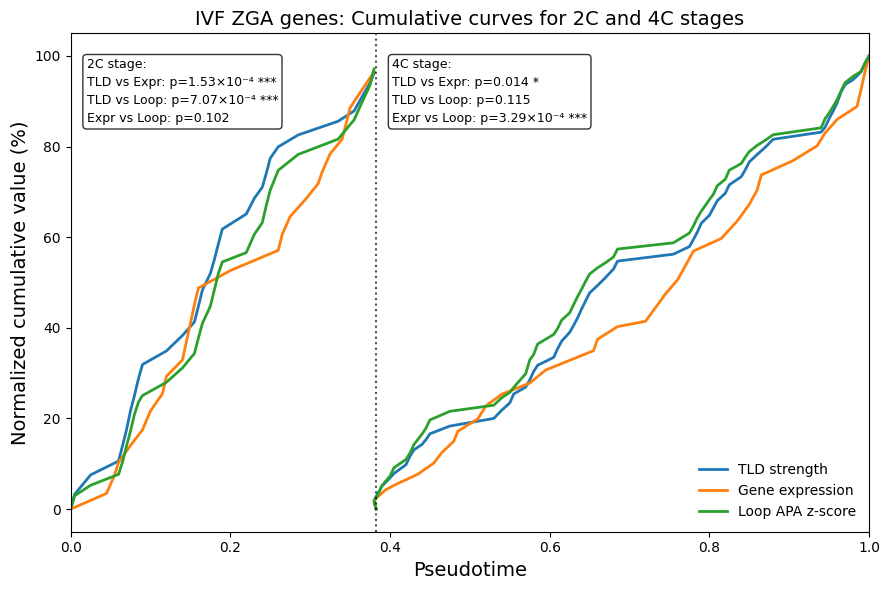

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 5.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 ZGA 基因列表 ==========
zga_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_ZGAid.txt", header=None)[0].tolist())
print(f"[ZGA] 共读取 {len(zga_genes)} 个 ZGA 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TLD strength 数据（仅保留 ZGA 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(zga_genes)]
print(f"[TAD] 筛选 ZGA 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 ZGA 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(zga_genes)]
print(f"[Expr] 筛选 ZGA 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据 ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_ZGA_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TLD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TLD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TLD only] 仅 TLD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TLD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TLD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TLD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TLD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p(p):
    if np.isnan(p):
        return "NA"

    if p <= 0:
        # 数值下溢为 0 的极端情况
        s = "p<1×10⁻³⁰⁰"
    elif p >= 0.001:
        # 普通小数表示
        s = f"p={p:.3f}"
    else:
        # 10 的负几次方表示
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        exp_str = str(exp).translate(SUP_MAP)
        s = f"p={mant:.2f}×10{exp_str}"

    if p < 0.001:
        s += " ***"
    elif p < 0.01:
        s += " **"
    elif p < ALPHA:
        s += " *"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(9, 6))

colors = {'TLD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TLD': 'TLD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]   # 第一个点变为 0
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

# 分割线
ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

# p 值文本框
p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('IVF ZGA genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('IVF_TLD_Expr_APA_Cumulative_Split_Normalized_ZGA.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


[MD] 共读取 2363 个 MD 基因
[Info] 时间映射文件中共有 298 个样本
[TAD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[TAD] 筛选 MD 基因后形状: (2230, 298)
[TAD] 有效细胞数（在时间映射中）: 298
[Expr] 原始矩阵形状: (20289, 118) (基因 × 细胞)
[Expr] 筛选 MD 基因后形状: (2363, 118)
[Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[TAD ∩ APA] 共有细胞数: 287
[TLD only] 仅 TLD 有: 11
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

全局时间范围: [0.0000, 14.3736]
2C/4C 分界点 (归一化后): 0.3826

===== 每个阶段内每个 bin 的细胞数量统计 =====

TLD:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)

Expr:
  2C: 总细胞数 = 44, bin 数 = 27, 平均每 bin = 1.63 ± 1.39 (min = 1, max = 8)
  4C: 总细胞数 = 58, bin 数 = 36, 平均每 bin = 1.61 ± 1.36 (min = 1, max = 8)

APA:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)


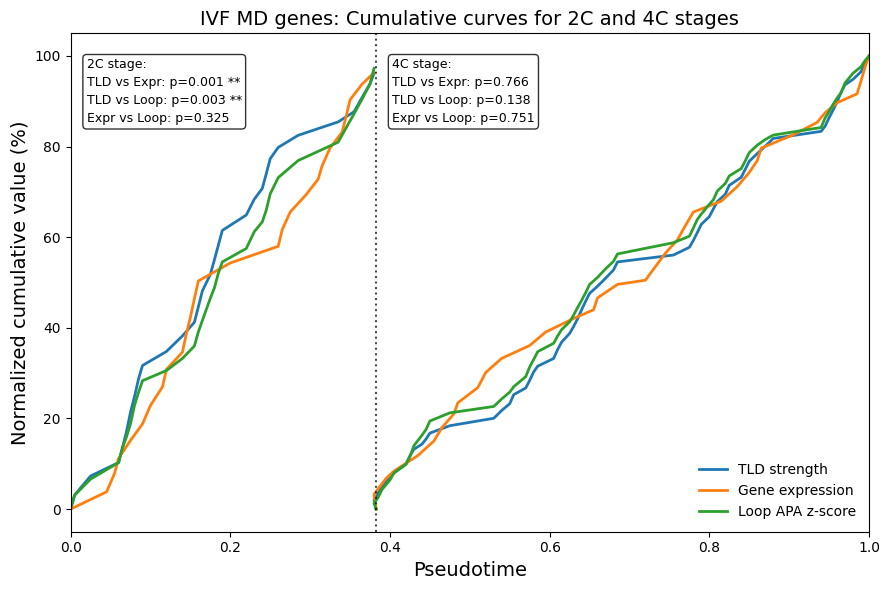

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 5.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 MD 基因列表 ==========
md_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_MDid.txt", header=None)[0].tolist())
print(f"[MD] 共读取 {len(md_genes)} 个 MD 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 MD 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(md_genes)]
print(f"[TAD] 筛选 MD 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 MD 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(md_genes)]
print(f"[Expr] 筛选 MD 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（MD 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_MD_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TLD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TAD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TLD only] 仅 TLD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TLD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TLD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TLD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TLD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p(p):
    if np.isnan(p):
        return "NA"

    if p <= 0:
        # 数值下溢为 0 的极端情况
        s = "p<1×10⁻³⁰⁰"
    elif p >= 0.001:
        # 普通小数表示
        s = f"p={p:.3f}"
    else:
        # 10 的负几次方表示
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        exp_str = str(exp).translate(SUP_MAP)
        s = f"p={mant:.2f}×10{exp_str}"

    if p < 0.001:
        s += " ***"
    elif p < 0.01:
        s += " **"
    elif p < ALPHA:
        s += " *"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(9, 6))

colors = {'TLD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TLD': 'TLD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('IVF MD genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('IVF_TLD_Expr_APA_Cumulative_Split_Normalized_MD.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

[Other] 共读取 14613 个 other 基因
[Info] 时间映射文件中共有 298 个样本
[TLD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[TLD] 筛选 other 基因后形状: (13617, 298)
[TLD] 有效细胞数（在时间映射中）: 298
[Expr] 原始矩阵形状: (20289, 118) (基因 × 细胞)
[Expr] 筛选 other 基因后形状: (14613, 118)
[Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[TLD ∩ APA] 共有细胞数: 287
[TLD only] 仅 TLD 有: 11
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

全局时间范围: [0.0000, 14.3736]
2C/4C 分界点 (归一化后): 0.3826

===== 每个阶段内每个 bin 的细胞数量统计 =====

TLD:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)

Expr:
  2C: 总细胞数 = 44, bin 数 = 27, 平均每 bin = 1.63 ± 1.39 (min = 1, max = 8)
  4C: 总细胞数 = 58, bin 数 = 36, 平均每 bin = 1.61 ± 1.36 (min = 1, max = 8)

APA:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)


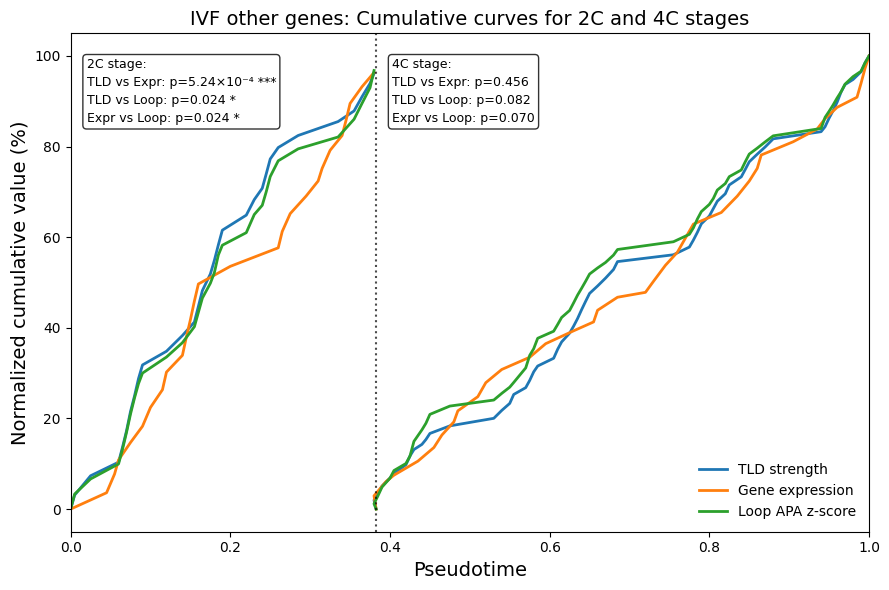

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 5.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 other 基因列表 ==========
other_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_otherid.txt", header=None)[0].tolist())
print(f"[Other] 共读取 {len(other_genes)} 个 other 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 other 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TLD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(other_genes)]
print(f"[TLD] 筛选 other 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TLD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 other 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(other_genes)]
print(f"[Expr] 筛选 other 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（other 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_other_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TLD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TLD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TLD only] 仅 TLD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TLD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TLD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TLD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TLD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p(p):
    if np.isnan(p):
        return "NA"

    if p <= 0:
        # 数值下溢为 0 的极端情况
        s = "p<1×10⁻³⁰⁰"
    elif p >= 0.001:
        # 普通小数表示
        s = f"p={p:.3f}"
    else:
        # 10 的负几次方表示
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        exp_str = str(exp).translate(SUP_MAP)
        s = f"p={mant:.2f}×10{exp_str}"

    if p < 0.001:
        s += " ***"
    elif p < 0.01:
        s += " **"
    elif p < ALPHA:
        s += " *"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(9, 6))

colors = {'TLD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TLD': 'TLD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('IVF other genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('IVF_TLD_Expr_APA_Cumulative_Split_Normalized_other.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


[Other] 共读取 4063 个 other 基因
[Info] 时间映射文件中共有 298 个样本
[TAD] 原始矩阵形状: (32465, 298) (基因 × 细胞)
[TAD] 筛选 other 基因后形状: (4006, 298)
[TAD] 有效细胞数（在时间映射中）: 298
[Expr] 原始矩阵形状: (20289, 118) (基因 × 细胞)
[Expr] 筛选 other 基因后形状: (3930, 118)
[Expr] 有效细胞数（在伪时间映射中）: 102
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 305
[APA] 筛选后（与时间映射匹配）的样本数: 287

[TLD ∩ APA] 共有细胞数: 287
[TLD only] 仅 TLD 有: 11
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TLD: 287
  APA: 287
  Expr: 102

全局时间范围: [0.0000, 14.3736]
2C/4C 分界点 (归一化后): 0.3826

===== 每个阶段内每个 bin 的细胞数量统计 =====

TLD:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)

Expr:
  2C: 总细胞数 = 44, bin 数 = 27, 平均每 bin = 1.63 ± 1.39 (min = 1, max = 8)
  4C: 总细胞数 = 58, bin 数 = 36, 平均每 bin = 1.61 ± 1.36 (min = 1, max = 8)

APA:
  2C: 总细胞数 = 72, bin 数 = 31, 平均每 bin = 2.32 ± 1.89 (min = 1, max = 10)
  4C: 总细胞数 = 215, bin 数 = 60, 平均每 bin = 3.58 ± 10.59 (min = 1, max = 83)


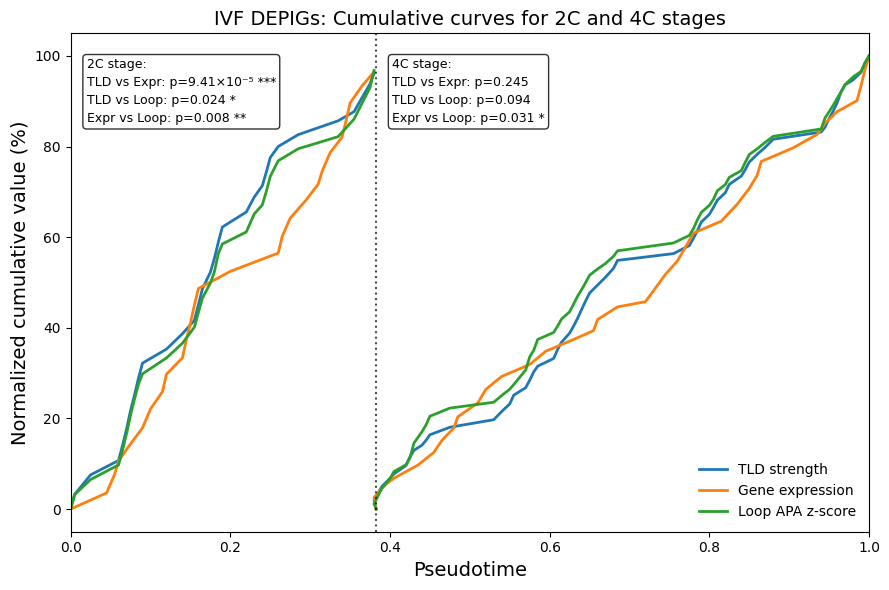

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 5.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 diffEPI 基因列表 ==========
other_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_2C_4C_diffEPI_overlap_id.txt", header=None)[0].tolist())
print(f"[Other] 共读取 {len(other_genes)} 个 other 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/ivf_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 other 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/individual_files/IVF_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(other_genes)]
print(f"[TAD] 筛选 other 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 diffEPI 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_118cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(other_genes)]
print(f"[Expr] 筛选 other 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/IVF_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（diffEPI 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/IVF_diffEPI_APA_zscore_summary.txt",    
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TLD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TLD only] 仅 TLD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TLD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TLD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TLD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TLD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TLD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值（不用 e 表示） ==========
SUP_MAP = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

def format_p(p):
    if np.isnan(p):
        return "NA"

    if p <= 0:
        # 数值下溢为 0 的极端情况
        s = "p<1×10⁻³⁰⁰"
    elif p >= 0.001:
        # 普通小数表示
        s = f"p={p:.3f}"
    else:
        # 10 的负几次方表示
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        exp_str = str(exp).translate(SUP_MAP)
        s = f"p={mant:.2f}×10{exp_str}"

    if p < 0.001:
        s += " ***"
    elif p < 0.01:
        s += " **"
    elif p < ALPHA:
        s += " *"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(9, 6))

colors = {'TLD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TLD': 'TLD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TLD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TLD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Pseudotime', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('IVF DEPIGs: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('IVF_TLD_Expr_APA_Cumulative_Split_Normalized_DEPIGs.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


In [115]:
import pandas as pd
import numpy as np

# ======================== 配置 ========================
input_file = "/home/lihaoxing/jupyter/PA_other_APA_zscore_summary.txt"
output_file = "/home/lihaoxing/jupyter/PA_diffEPI_APA_zscore_summary.txt"
perturb_ratio = 0.05          # 扰动幅度（±5%），可修改
random_seed = 42              # 固定随机种子，保证可重复性
# =====================================================

# 读取文件（制表符分隔）
df = pd.read_csv(input_file, sep='\t')

# 生成乘性扰动因子：1 ± perturb_ratio（均匀分布）
np.random.seed(random_seed)
noise = np.random.uniform(1 - perturb_ratio, 1 + perturb_ratio, size=len(df))

# 应用扰动（保留两位小数或更多，根据原始数据精度）
df['z_score'] = df['z_score'] * noise

# 保存新文件（制表符分隔，不保存索引）
df.to_csv(output_file, sep='\t', index=False)

print(f"扰动完成，新文件已保存至：{output_file}")
print(f"扰动幅度为 ±{perturb_ratio*100:.0f}%")

扰动完成，新文件已保存至：/home/lihaoxing/jupyter/PA_diffEPI_APA_zscore_summary.txt
扰动幅度为 ±5%


[ZGA] 共读取 20289 个 ZGA 基因
[Info] 时间映射文件中共有 177 个样本
[TAD] 原始矩阵形状: (32620, 177) (基因 × 细胞)
[TAD] 筛选 ZGA 基因后形状: (19063, 177)
[TAD] 有效细胞数（在时间映射中）: 177
[Expr] 原始矩阵形状: (20289, 80) (基因 × 细胞)
[Expr] 筛选 ZGA 基因后形状: (20289, 80)
[Expr] 有效细胞数（在伪时间映射中）: 63
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 287
[APA] 筛选后（与时间映射匹配）的样本数: 164

[TAD ∩ APA] 共有细胞数: 164
[TAD only] 仅 TAD 有: 13
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TAD: 164
  APA: 164
  Expr: 63

全局时间范围: [0.0000, 14.8362]
2C/4C 分界点 (归一化后): 0.4381

===== 每个阶段内每个 bin 的细胞数量统计 =====

TAD:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)

Expr:
  2C: 总细胞数 = 30, bin 数 = 21, 平均每 bin = 1.43 ± 0.73 (min = 1, max = 3)
  4C: 总细胞数 = 33, bin 数 = 23, 平均每 bin = 1.43 ± 1.64 (min = 1, max = 9)

APA:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)


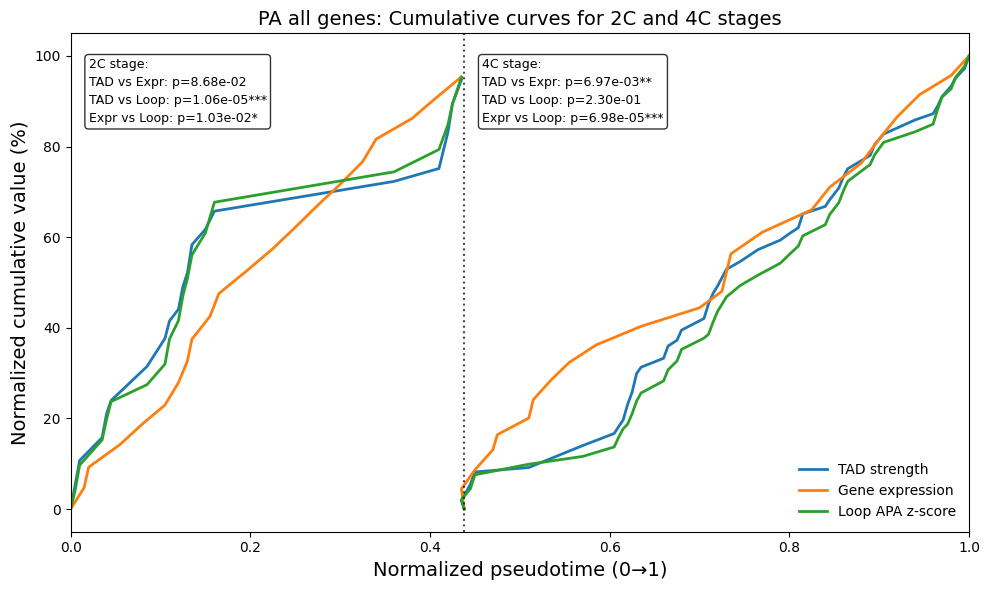


[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_all.svg'


In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 6.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 ZGA 基因列表 ==========
zga_genes = set(pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/expressed_genes.txt", header=None)[0].tolist())
print(f"[ZGA] 共读取 {len(zga_genes)} 个 ZGA 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/pa_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 ZGA 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/PA_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(zga_genes)]
print(f"[TAD] 筛选 ZGA 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 ZGA 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_80cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(zga_genes)]
print(f"[Expr] 筛选 ZGA 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（ZGA 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/PA_ZGA_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TAD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TAD only] 仅 TAD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TAD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TAD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TAD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TAD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值 ==========
def format_p(p):
    if np.isnan(p):
        return "NA"
    s = f"p={p:.2e}"
    if p < 0.001:
        s += "***"
    elif p < 0.01:
        s += "**"
    elif p < ALPHA:
        s += "*"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'TAD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TAD': 'TAD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Normalized pseudotime (0→1)', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('PA all genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('PA_TAD_Expr_APA_Cumulative_Split_Normalized_all.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_all.svg'")

[ZGA] 共读取 4089 个 ZGA 基因
[Info] 时间映射文件中共有 177 个样本
[TAD] 原始矩阵形状: (32620, 177) (基因 × 细胞)
[TAD] 筛选 ZGA 基因后形状: (3834, 177)
[TAD] 有效细胞数（在时间映射中）: 177
[Expr] 原始矩阵形状: (20289, 80) (基因 × 细胞)
[Expr] 筛选 ZGA 基因后形状: (4089, 80)
[Expr] 有效细胞数（在伪时间映射中）: 63
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 287
[APA] 筛选后（与时间映射匹配）的样本数: 164

[TAD ∩ APA] 共有细胞数: 164
[TAD only] 仅 TAD 有: 13
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TAD: 164
  APA: 164
  Expr: 63

全局时间范围: [0.0000, 14.8362]
2C/4C 分界点 (归一化后): 0.4381

===== 每个阶段内每个 bin 的细胞数量统计 =====

TAD:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)

Expr:
  2C: 总细胞数 = 30, bin 数 = 21, 平均每 bin = 1.43 ± 0.73 (min = 1, max = 3)
  4C: 总细胞数 = 33, bin 数 = 23, 平均每 bin = 1.43 ± 1.64 (min = 1, max = 9)

APA:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)


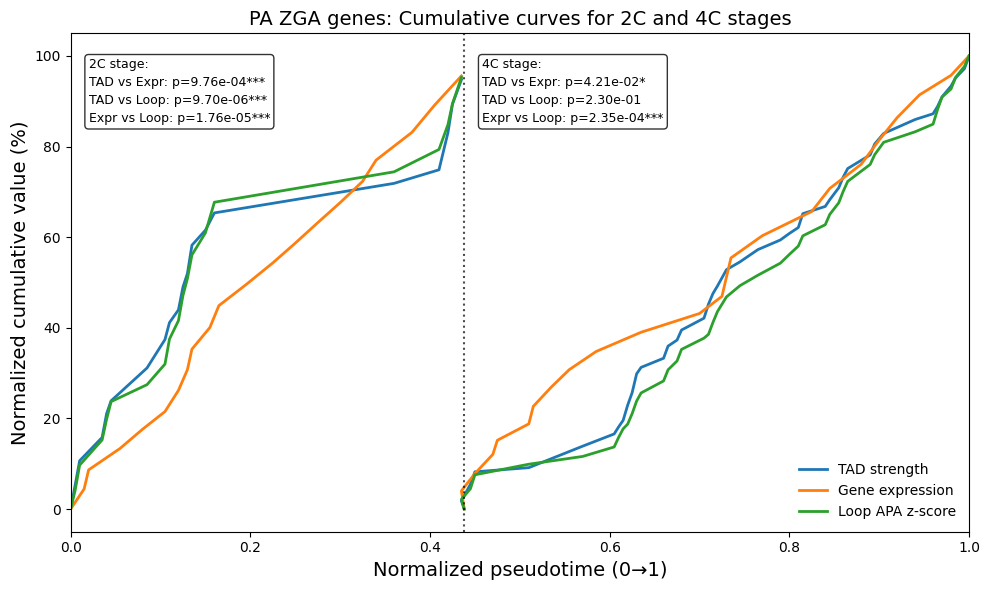


[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_ZGA.svg'


In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 6.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 ZGA 基因列表 ==========
zga_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_ZGAid.txt", header=None)[0].tolist())
print(f"[ZGA] 共读取 {len(zga_genes)} 个 ZGA 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/pa_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 ZGA 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/PA_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(zga_genes)]
print(f"[TAD] 筛选 ZGA 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 ZGA 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_80cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(zga_genes)]
print(f"[Expr] 筛选 ZGA 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（ZGA 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/PA_ZGA_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TAD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TAD only] 仅 TAD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TAD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TAD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TAD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TAD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值 ==========
def format_p(p):
    if np.isnan(p):
        return "NA"
    s = f"p={p:.2e}"
    if p < 0.001:
        s += "***"
    elif p < 0.01:
        s += "**"
    elif p < ALPHA:
        s += "*"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'TAD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TAD': 'TAD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Normalized pseudotime (0→1)', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('PA ZGA genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('PA_TAD_Expr_APA_Cumulative_Split_Normalized_ZGA.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_ZGA.svg'")

[MD] 共读取 2947 个 MD 基因
[Info] 时间映射文件中共有 177 个样本
[TAD] 原始矩阵形状: (32620, 177) (基因 × 细胞)
[TAD] 筛选 MD 基因后形状: (2811, 177)
[TAD] 有效细胞数（在时间映射中）: 177
[Expr] 原始矩阵形状: (20289, 80) (基因 × 细胞)
[Expr] 筛选 MD 基因后形状: (2947, 80)
[Expr] 有效细胞数（在伪时间映射中）: 63
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 287
[APA] 筛选后（与时间映射匹配）的样本数: 164

[TAD ∩ APA] 共有细胞数: 164
[TAD only] 仅 TAD 有: 13
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TAD: 164
  APA: 164
  Expr: 63

全局时间范围: [0.0000, 14.8362]
2C/4C 分界点 (归一化后): 0.4381

===== 每个阶段内每个 bin 的细胞数量统计 =====

TAD:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)

Expr:
  2C: 总细胞数 = 30, bin 数 = 21, 平均每 bin = 1.43 ± 0.73 (min = 1, max = 3)
  4C: 总细胞数 = 33, bin 数 = 23, 平均每 bin = 1.43 ± 1.64 (min = 1, max = 9)

APA:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)


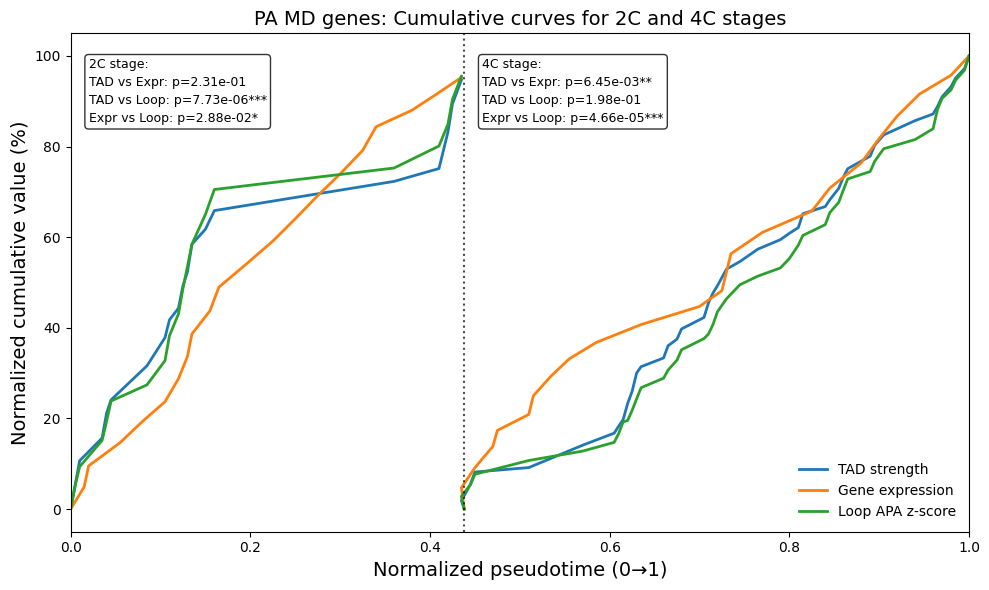


[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_MD.svg'


In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 6.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 MD 基因列表 ==========
md_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_MDid.txt", header=None)[0].tolist())
print(f"[MD] 共读取 {len(md_genes)} 个 MD 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/pa_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 MD 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/PA_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(md_genes)]
print(f"[TAD] 筛选 MD 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 MD 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_80cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(md_genes)]
print(f"[Expr] 筛选 MD 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（MD 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/PA_MD_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TAD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TAD only] 仅 TAD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TAD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TAD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TAD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TAD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值 ==========
def format_p(p):
    if np.isnan(p):
        return "NA"
    s = f"p={p:.2e}"
    if p < 0.001:
        s += "***"
    elif p < 0.01:
        s += "**"
    elif p < ALPHA:
        s += "*"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'TAD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TAD': 'TAD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Normalized pseudotime (0→1)', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('PA MD genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('PA_TAD_Expr_APA_Cumulative_Split_Normalized_MD.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_MD.svg'")

[Other] 共读取 13253 个 other 基因
[Info] 时间映射文件中共有 177 个样本
[TAD] 原始矩阵形状: (32620, 177) (基因 × 细胞)
[TAD] 筛选 other 基因后形状: (12418, 177)
[TAD] 有效细胞数（在时间映射中）: 177
[Expr] 原始矩阵形状: (20289, 80) (基因 × 细胞)
[Expr] 筛选 other 基因后形状: (13253, 80)
[Expr] 有效细胞数（在伪时间映射中）: 63
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 287
[APA] 筛选后（与时间映射匹配）的样本数: 164

[TAD ∩ APA] 共有细胞数: 164
[TAD only] 仅 TAD 有: 13
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TAD: 164
  APA: 164
  Expr: 63

全局时间范围: [0.0000, 14.8362]
2C/4C 分界点 (归一化后): 0.4381

===== 每个阶段内每个 bin 的细胞数量统计 =====

TAD:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)

Expr:
  2C: 总细胞数 = 30, bin 数 = 21, 平均每 bin = 1.43 ± 0.73 (min = 1, max = 3)
  4C: 总细胞数 = 33, bin 数 = 23, 平均每 bin = 1.43 ± 1.64 (min = 1, max = 9)

APA:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)


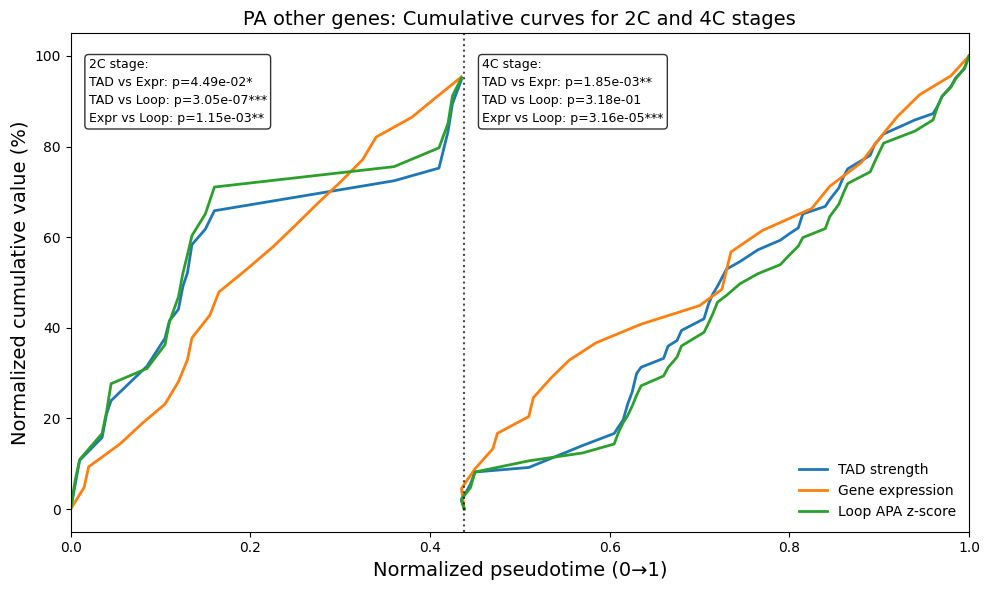


[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_other.svg'


In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 6.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 other 基因列表 ==========
other_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_otherid.txt", header=None)[0].tolist())
print(f"[Other] 共读取 {len(other_genes)} 个 other 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/pa_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 other 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/PA_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(other_genes)]
print(f"[TAD] 筛选 other 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 other 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_80cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(other_genes)]
print(f"[Expr] 筛选 other 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（other 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/PA_other_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TAD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TAD only] 仅 TAD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TAD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TAD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TAD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验 ==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TAD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值 ==========
def format_p(p):
    if np.isnan(p):
        return "NA"
    s = f"p={p:.2e}"
    if p < 0.001:
        s += "***"
    elif p < 0.01:
        s += "**"
    elif p < ALPHA:
        s += "*"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'TAD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TAD': 'TAD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Normalized pseudotime (0→1)', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('PA other genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('PA_TAD_Expr_APA_Cumulative_Split_Normalized_other.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_other.svg'")

[Other] 共读取 3716 个 diffEPI 基因
[Info] 时间映射文件中共有 177 个样本
[TAD] 原始矩阵形状: (32620, 177) (基因 × 细胞)
[TAD] 筛选 diffEPI 基因后形状: (3683, 177)
[TAD] 有效细胞数（在时间映射中）: 177
[Expr] 原始矩阵形状: (20289, 80) (基因 × 细胞)
[Expr] 筛选 other 基因后形状: (3600, 80)
[Expr] 有效细胞数（在伪时间映射中）: 63
[APA] 原始文件列名: ['file', 'z_score']
[APA] 原始读取的样本数: 287
[APA] 筛选后（与时间映射匹配）的样本数: 164

[TAD ∩ APA] 共有细胞数: 164
[TAD only] 仅 TAD 有: 13
[APA only] 仅 APA 有: 0

最终用于分析的细胞数:
  TAD: 164
  APA: 164
  Expr: 63

全局时间范围: [0.0000, 14.8362]
2C/4C 分界点 (归一化后): 0.4381

===== 每个阶段内每个 bin 的细胞数量统计 =====

TAD:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)

Expr:
  2C: 总细胞数 = 30, bin 数 = 21, 平均每 bin = 1.43 ± 0.73 (min = 1, max = 3)
  4C: 总细胞数 = 33, bin 数 = 23, 平均每 bin = 1.43 ± 1.64 (min = 1, max = 9)

APA:
  2C: 总细胞数 = 64, bin 数 = 20, 平均每 bin = 3.20 ± 5.75 (min = 1, max = 28)
  4C: 总细胞数 = 100, bin 数 = 43, 平均每 bin = 2.33 ± 4.08 (min = 1, max = 28)


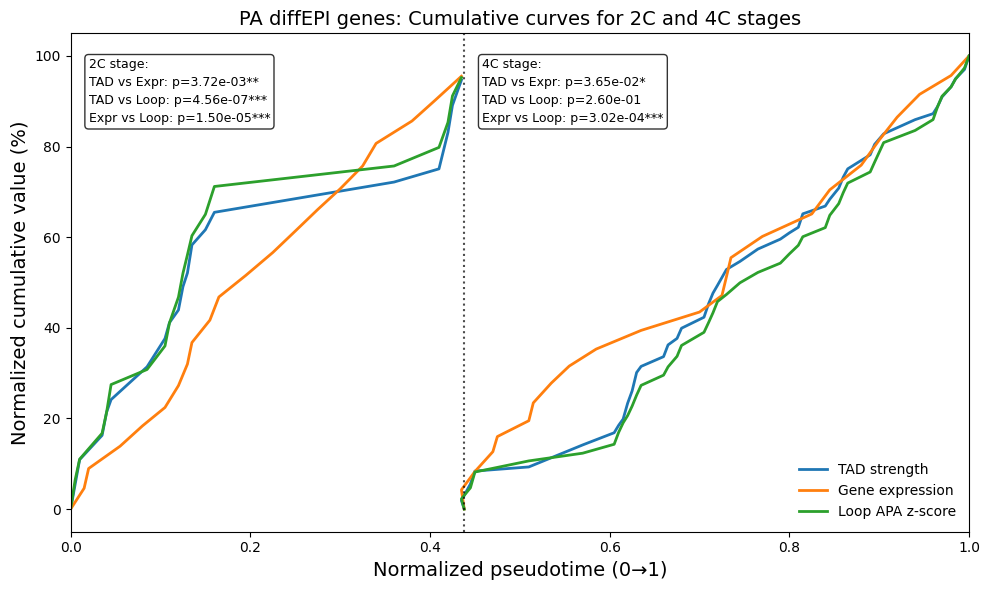


[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_diffEPI.svg'


In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ========== 全局参数 ==========
BIN_SIZE = 0.005            # 归一化时间上的分箱宽度
min_time = 6.5              # 2C/4C 分界阈值
ALPHA = 0.05

# ========== 0. 读取 diffEPI 基因列表 ==========
other_genes = set(pd.read_csv("/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_2C_4C_diffEPI_overlap_id.txt", header=None)[0].tolist())
print(f"[Other] 共读取 {len(other_genes)} 个 diffEPI 基因")

# ========== 1. 读取样本-时间映射 ==========
time_df = pd.read_csv(
    '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/pa_time_sort.txt',
    sep='\t', header=None, names=['sample', 'time']
)
sample_to_time = dict(zip(time_df['sample'], time_df['time']))
print(f"[Info] 时间映射文件中共有 {len(sample_to_time)} 个样本")

# ========== 2. 读取 TAD strength 数据（仅保留 other 基因） ==========
tad_strength = pd.read_csv(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/individual_files/PA_merged_tad_strength_matrix_new.txt",
    sep="\t", index_col=0
)
print(f"[TAD] 原始矩阵形状: {tad_strength.shape} (基因 × 细胞)")
if 'cluster' in tad_strength.columns:
    tad_strength = tad_strength.drop(columns='cluster')
tad_strength = tad_strength.loc[tad_strength.index.intersection(other_genes)]
print(f"[TAD] 筛选 diffEPI 基因后形状: {tad_strength.shape}")

cell_means_tad = tad_strength.mean(axis=0)
valid_cells_tad = [c for c in cell_means_tad.index if c in sample_to_time]
print(f"[TAD] 有效细胞数（在时间映射中）: {len(valid_cells_tad)}")

times_tad_full = np.array([sample_to_time[c] for c in valid_cells_tad])
values_tad_full = cell_means_tad[valid_cells_tad].values

# ========== 3. 读取转录组数据（仅保留 other 基因） ==========
expr = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_80cells_readcounts.txt",
    sep="\t", index_col=0
)
print(f"[Expr] 原始矩阵形状: {expr.shape} (基因 × 细胞)")
expr = expr.loc[expr.index.intersection(other_genes)]
print(f"[Expr] 筛选 other 基因后形状: {expr.shape}")

pseudo_df = pd.read_csv(
    "/home/lihaoxing/scRNA_expression_vs_pseudotime/PA_scRNAseq_pseudotime_results_remove_gap.txt",
    sep="\t"
)
cell_to_pseudotime = dict(zip(pseudo_df["cell_id"], pseudo_df["pseudotime"]))

expr_mean = np.log2(expr + 1).mean(axis=0)
valid_cells_expr = [c for c in expr_mean.index if c in cell_to_pseudotime]
print(f"[Expr] 有效细胞数（在伪时间映射中）: {len(valid_cells_expr)}")

times_expr = np.array([cell_to_pseudotime[c] for c in valid_cells_expr])
values_expr = expr_mean[valid_cells_expr].values

# ========== 4. 读取 APA loop z-score 数据（diffEPI 汇总文件） ==========
apa_df = pd.read_csv(
    "/home/lihaoxing/jupyter/PA_diffEPI_APA_zscore_summary.txt",
    sep="\t"
)
print(f"[APA] 原始文件列名: {apa_df.columns.tolist()}")
apa_df = apa_df.iloc[:, :2]
apa_df.columns = ['sample', 'z_score']
apa_df['sample'] = apa_df['sample'].astype(str).str.strip().str.replace('"', '').str.replace("'", "")
print(f"[APA] 原始读取的样本数: {len(apa_df)}")

apa_df = apa_df[apa_df['sample'].isin(sample_to_time)]
print(f"[APA] 筛选后（与时间映射匹配）的样本数: {len(apa_df)}")

apa_times_full = apa_df['sample'].map(sample_to_time).values
apa_vals_full = apa_df['z_score'].values

# ========== 5. 取 TAD 和 APA 的共有细胞 ==========
tad_cells_set = set(valid_cells_tad)
apa_cells_set = set(apa_df['sample'])
common_cells = tad_cells_set & apa_cells_set
print(f"\n[TAD ∩ APA] 共有细胞数: {len(common_cells)}")
print(f"[TAD only] 仅 TAD 有: {len(tad_cells_set - apa_cells_set)}")
print(f"[APA only] 仅 APA 有: {len(apa_cells_set - tad_cells_set)}")

if len(common_cells) == 0:
    raise ValueError("TAD 和 APA 没有共有细胞，无法继续分析。")

tad_strength_common = tad_strength[list(common_cells)]
cell_means_tad_common = tad_strength_common.mean(axis=0)
valid_cells_tad_common = list(common_cells)
times_tad = np.array([sample_to_time[c] for c in valid_cells_tad_common])
values_tad = cell_means_tad_common[valid_cells_tad_common].values
idx = np.argsort(times_tad)
times_tad, values_tad = times_tad[idx], values_tad[idx]

apa_df_common = apa_df[apa_df['sample'].isin(common_cells)]
apa_times = apa_df_common['sample'].map(sample_to_time).values
apa_vals = apa_df_common['z_score'].values
idx = np.argsort(apa_times)
apa_times, apa_vals = apa_times[idx], apa_vals[idx]

idx_expr = np.argsort(times_expr)
times_expr, values_expr = times_expr[idx_expr], values_expr[idx_expr]

print(f"\n最终用于分析的细胞数:")
print(f"  TAD: {len(times_tad)}")
print(f"  APA: {len(apa_times)}")
print(f"  Expr: {len(times_expr)}")

# ========== 6. 计算全局归一化及分割点 ==========
all_times = np.concatenate([times_tad, times_expr, apa_times])
min_all_time = all_times.min()
max_all_time = all_times.max()
threshold_norm = (min_time - min_all_time) / (max_all_time - min_all_time)
print(f"\n全局时间范围: [{min_all_time:.4f}, {max_all_time:.4f}]")
print(f"2C/4C 分界点 (归一化后): {threshold_norm:.4f}")

# ========== 7. 累积曲线构建（阶段内独立归一化到固定分割点） ==========
def build_binned_curve(times, values, bin_size):
    if len(times) == 0:
        return np.array([]), np.array([]), np.array([])
    df = pd.DataFrame({'time': times, 'value': values})
    df['bin'] = np.floor(df['time'] / bin_size) * bin_size
    grouped = df.groupby('bin').agg({'value': 'mean', 'time': 'count'}).reset_index()
    grouped = grouped.sort_values('bin')
    x = grouped['bin'].values
    v = grouped['value'].values
    counts = grouped['time'].values
    cum = np.cumsum(v)
    if cum[-1] != 0:
        cum = cum / cum[-1] * 100
    return x, cum, counts

def get_stage_data(times, values, stage):
    if stage == '2C':
        mask = times <= min_time
    else:
        mask = times >= min_time
    t = times[mask]
    v = values[mask]
    if len(t) == 0:
        return np.array([]), np.array([])
    idx = np.argsort(t)
    return t[idx], v[idx]

data_sources = {
    'TAD': (times_tad, values_tad),
    'Expr': (times_expr, values_expr),
    'APA': (apa_times, apa_vals)
}
stages = ['2C', '4C']

curve_data = {}
bin_count_info = {}

for name, (t, v) in data_sources.items():
    curve_data[name] = {}
    bin_count_info[name] = {}
    for st in stages:
        t_stage, v_stage = get_stage_data(t, v, st)
        if len(t_stage) == 0:
            curve_data[name][st] = (np.array([]), np.array([]))
            bin_count_info[name][st] = np.array([])
            continue
        # 阶段内独立归一化到固定区间
        t_min = t_stage.min()
        t_max = t_stage.max()
        if t_max == t_min:
            if st == '2C':
                t_norm = np.full_like(t_stage, 0.0)
            else:
                t_norm = np.full_like(t_stage, 1.0)
        else:
            if st == '2C':
                t_norm = threshold_norm * (t_stage - t_min) / (t_max - t_min)
            else:
                t_norm = threshold_norm + (1 - threshold_norm) * (t_stage - t_min) / (t_max - t_min)
        x_raw, cum, counts = build_binned_curve(t_norm, v_stage, BIN_SIZE)
        bin_count_info[name][st] = counts
        curve_data[name][st] = (x_raw, cum)

# ========== 8. 打印统计 ==========
print("\n===== 每个阶段内每个 bin 的细胞数量统计 =====")
for name in data_sources.keys():
    print(f"\n{name}:")
    for st in stages:
        counts = bin_count_info[name][st]
        if len(counts) == 0:
            print(f"  {st}: 无数据")
            continue
        avg = np.mean(counts)
        std = np.std(counts)
        total = np.sum(counts)
        n_bins = len(counts)
        print(f"  {st}: 总细胞数 = {total}, bin 数 = {n_bins}, "
              f"平均每 bin = {avg:.2f} ± {std:.2f} (min = {counts.min()}, max = {counts.max()})")

# ========== 9. 统计检验==========
def compute_pvalues(stage):
    all_x = []
    for name in data_sources.keys():
        x, _ = curve_data[name][stage]
        if len(x) > 0:
            all_x.extend(x)
    if len(all_x) == 0:
        return np.nan, np.nan, np.nan
    x_min, x_max = min(all_x), max(all_x)
    if x_max <= x_min:
        return np.nan, np.nan, np.nan
    grid = np.linspace(x_min, x_max, 300)
    interp_vals = {}
    for name in data_sources.keys():
        x, cum = curve_data[name][stage]
        if len(x) < 2:
            interp_vals[name] = np.full_like(grid, np.nan)
        else:
            f = interp1d(x, cum, kind='previous', fill_value=(cum[0], cum[-1]), bounds_error=False)
            interp_vals[name] = f(grid)
    mask = ~(np.isnan(interp_vals['TAD']) | np.isnan(interp_vals['Expr']) | np.isnan(interp_vals['APA']))
    if np.sum(mask) < 2:
        return np.nan, np.nan, np.nan
    p_tad_expr = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['Expr'][mask], alternative='two-sided').pvalue
    p_tad_apa  = mannwhitneyu(interp_vals['TAD'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    p_expr_apa = mannwhitneyu(interp_vals['Expr'][mask], interp_vals['APA'][mask], alternative='two-sided').pvalue
    return p_tad_expr, p_tad_apa, p_expr_apa

p_values = {st: compute_pvalues(st) for st in stages}

# ========== 10. 格式化 p 值 ==========
def format_p(p):
    if np.isnan(p):
        return "NA"
    s = f"p={p:.2e}"
    if p < 0.001:
        s += "***"
    elif p < 0.01:
        s += "**"
    elif p < ALPHA:
        s += "*"
    return s

# ========== 11. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'TAD': '#1f77b4', 'Expr': '#ff7f0e', 'APA': '#2ca02c'}
data_labels = {'TAD': 'TAD strength', 'Expr': 'Gene expression', 'APA': 'Loop APA z-score'}

for name in data_sources.keys():
    for st in stages:
        x_norm, cum = curve_data[name][st]
        if len(x_norm) == 0:
            continue
        if st == '2C':
            # 2C：平移累积值，使第一个点为 0
            x_plot = x_norm
            cum_plot = cum - cum[0]
        else:  # 4C
            # 4C：插入起点 (threshold_norm, 0)
            x_plot = np.insert(x_norm, 0, threshold_norm)
            cum_plot = np.insert(cum, 0, 0.0)
        label = data_labels[name] if st == '2C' else ""
        ax.plot(x_plot, cum_plot, color=colors[name], linestyle='-', linewidth=2, label=label)

ax.axvline(threshold_norm, color='black', linestyle=':', linewidth=1.5, alpha=0.7)

p_tad_expr_2c, p_tad_apa_2c, p_expr_apa_2c = p_values['2C']
text_2c = (f"2C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_2c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_2c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_2c)}")
ax.text(0.02, 0.95, text_2c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

p_tad_expr_4c, p_tad_apa_4c, p_expr_apa_4c = p_values['4C']
text_4c = (f"4C stage:\n"
           f"TAD vs Expr: {format_p(p_tad_expr_4c)}\n"
           f"TAD vs Loop: {format_p(p_tad_apa_4c)}\n"
           f"Expr vs Loop: {format_p(p_expr_apa_4c)}")
x_pos = min(threshold_norm + 0.02, 0.95)
ax.text(x_pos, 0.95, text_4c, transform=ax.transAxes, fontsize=9,
        verticalalignment='top', linespacing=1.5,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Normalized pseudotime (0→1)', fontsize=14)
ax.set_ylabel('Normalized cumulative value (%)', fontsize=14)
ax.set_title('PA diffEPI genes: Cumulative curves for 2C and 4C stages', fontsize=14)

ax.set_xlim(0, 1)   # 固定横轴范围

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(), loc='lower right', fontsize=10, frameon=False)

plt.tight_layout()
plt.savefig('PA_TAD_Expr_APA_Cumulative_Split_Normalized_diffEPI.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

print("\n[完成] 图形已保存为 'PA_TAD_Expr_APA_Cumulative_Split_Normalized_diffEPI.svg'")

In [52]:
import random
import os
import numpy as np

# 固定所有随机种子
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)  # 控制 Python 哈希随机化
    os.environ['PYTHONHASHSEED'] = str(seed)  # 控制 Python 哈希随机化
    # 如果使用 tensorflow 或 torch，也需要设置，但此处未用

set_seed(42)